# 01. Chemical similarity to training drugs

Chemical similarity describes how closely a test drug’s molecular structure resembles a drug used in training. The audit placed drugs into five similarity groups and compared how well STATE recovered the genes that responded to each drug.

**Original agent determination:** No meaningful decline. HVG overlap@N was 0.013 higher in the least-similar bin than in the most-similar bin.

This notebook reconstructs the June primary run from its original downloads, split files, processing code and saved agent decisions. STATE was evaluated through the official scored-output repositories in that run.

**Portable input setup.** Install `../requirements.txt` in a Python3.11 environment. The first code cell restores the exact offline payloads included in this checkout, verifies their hashes, and then runs the original scored-output analysis. No model inference is performed. Historical saved curves remain visible; a clean run rebuilds its own `computed/` tables. See `../README.md`.

In [1]:
from pathlib import Path
import sys, json
root=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'recovered_pipeline.py').is_file())
sys.path.insert(0,str(root))
import pandas as pd
from IPython.display import display, Markdown
from state_inputs import ensure_inputs
print(ensure_inputs())
import recovered_pipeline as rp
import notebook_support as ns


{'profile': 'default', 'verified_files': 226, 'assets': [{'asset': 'state-historical-comparison-tables.tar.gz', 'members': 25, 'source': 'verified_existing_inputs'}, {'asset': 'state-official-score-cache.tar.gz', 'members': 193, 'source': 'verified_existing_inputs'}, {'asset': 'state-historical-annotations.tar.gz', 'members': 8, 'source': 'verified_existing_inputs'}], 'new_model_inference': False}


Matplotlib is building the font cache; this may take a moment.


## Original acquisition and inputs

The original downloader and processing scripts are preserved unchanged under `original/`. The replay resolves their downloads to the recovered cache at the recorded repository revisions, so no current dataset replaces the original bytes. Original downloads, processing and plotting are separate visible steps below.

In [2]:
verification=rp.run_stage('initial')
ns.show_acquisition('initial')


,repo,revision
0,arcinstitute/ST-HVG-Tahoe,ca6b751972493f8448e3256d1340ae70ad43e1e7
1,arcinstitute/ST-SE-Tahoe,03b1971d7cc93a7535fd2e957c6948dba267378b
2,arcinstitute/ST-HVG-Replogle,bb6a9562cbbf1fd152df14cc53b4cc7517c77175
3,arcinstitute/ST-SE-Replogle,e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c
4,arcinstitute/ST-HVG-Parse,827df657cd87063026d2abefd73e99036755ac1b
5,arcinstitute/ST-SE-Parse,fa458ffda8690c5c5bdff080dfdc46b46713043b
6,tahoebio/Tahoe-100M,2dc57900b7981cfcf5e211527169a0b006546a95


Original evaluation used official scored CSVs. The replay loads the original cached bytes at these revisions.
All 55 score filenames and the three metadata downloads are in computed/initial/artifacts/download_revisions.json.
Initial acquisition implementation: original/state_generalizability_20260602_single_controller/scripts/run_state_spectra_audit.py


## Original processing code

These are the original functions used for this analysis. `recovered_pipeline.py` changes their filesystem destinations and uses the original cached downloads; it writes regenerated products only to `computed/`. Set `force=True` in `run_stage` to recompute this stage after its prerequisites.

In [3]:
ns.show_code('initial',1)

/opt/homebrew/anaconda3/envs/fleming/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```python
def load_target_results(manifest):
    cache_dir = SPECTRA / "loaded_target_results"
    cache_dir.mkdir(parents=True, exist_ok=True)
    frames = []
    download_log = []
    for f in result_file_rows(manifest):
        repo = f["repo_id"]
        path = f["path"]
        local = hf_hub_download(repo_id=repo, filename=path, cache_dir=str(CACHE))
        df = pd.read_csv(local)
        dataset, protocol, context, split_id, rep = parse_result_path(repo, path)
        df.insert(0, "source_repo", repo)
        df.insert(1, "source_path", path)
        df.insert(2, "dataset_family", dataset)
        df.insert(3, "protocol", protocol)
        df.insert(4, "context", context)
        df.insert(5, "split_id", split_id)
        df.insert(6, "representation", rep)
        names, doses, units = zip(*[parse_perturbation(x) for x in df["perturbation"].tolist()])
        df["perturbation_name"] = names
        df["dose"] = doses
        df["dose_unit"] = units
        df["perturbation_norm"] = [norm_name(x) for x in names]
        df["perturbation_loose"] = [loose_name(x) for x in names]
        frames.append(df)
        download_log.append({"repo": repo, "path": path, "rows": int(len(df)), "bytes": f.get("size", 0), "local": local})
    all_df = pd.concat(frames, ignore_index=True)
    all_df.to_csv(ROOT / "target_model_results.csv", index=False)
    (ART / "loaded_target_results_manifest.json").write_text(json.dumps(download_log, indent=2))
    return all_df, download_log

```

```python
def load_tahoe_metadata():
    drug_path = hf_hub_download(
        repo_id="tahoebio/Tahoe-100M",
        repo_type="dataset",
        filename="metadata/drug_metadata.parquet",
        cache_dir=str(CACHE),
    )
    gene_path = hf_hub_download(
        repo_id="tahoebio/Tahoe-100M",
        repo_type="dataset",
        filename="metadata/gene_metadata.parquet",
        cache_dir=str(CACHE),
    )
    cell_path = hf_hub_download(
        repo_id="tahoebio/Tahoe-100M",
        repo_type="dataset",
        filename="metadata/cell_line_metadata.parquet",
        cache_dir=str(CACHE),
    )
    return pd.read_parquet(drug_path), pd.read_parquet(gene_path), pd.read_parquet(cell_path)

```

```python
def compute_context_chemical_axis(tahoe_df: pd.DataFrame, drug_meta: pd.DataFrame):
    toml_path = STATE / "state_preprint_toml_files" / "tahoe_tomls" / "generalization.toml"
    fewshot = parse_tahoe_fewshot_toml(toml_path)
    by_norm, by_loose = make_drug_lookup(drug_meta)
    drug_meta = drug_meta.copy()
    drug_meta["drug_norm"] = drug_meta["drug"].map(norm_name)
    drug_meta["drug_loose"] = drug_meta["drug"].map(loose_name)
    drug_meta["fingerprint"] = drug_meta["canonical_smiles"].map(fingerprint_from_smiles)
    fps_by_norm = {r["drug_norm"]: r["fingerprint"] for _, r in drug_meta.iterrows() if is_fingerprint(r["fingerprint"])}
    fps_by_loose = {r["drug_loose"]: r["fingerprint"] for _, r in drug_meta.iterrows() if is_fingerprint(r["fingerprint"])}

    def find_fp(norm, loose):
        fp = fps_by_norm.get(norm)
        if is_fingerprint(fp):
            return fp
        fp = fps_by_loose.get(loose)
        if is_fingerprint(fp):
            return fp
        return None

    all_drugs = set(drug_meta["drug_norm"])
    context_train = {}
    context_val = {}
    context_test = {}
    for context, spec in fewshot.items():
        val = {x["drug_norm"] for x in spec["val"]}
        test = {x["drug_norm"] for x in spec["test"]}
        context_val[context] = val
        context_test[context] = test
        context_train[context] = all_drugs - val - test

    sim_records = []
    for context, train_norms in context_train.items():
        train_fps = []
        for n in train_norms:
            rec = by_norm.get(n)
            if rec is None:
                continue
            fp = fingerprint_from_smiles(rec.get("canonical_smiles"))
            if fp is not None:
                train_fps.append((n, rec.get("drug"), fp))
        for _, row in tahoe_df[tahoe_df["context"] == context].iterrows():
            fp = find_fp(row["perturbation_norm"], row["perturbation_loose"])
            max_sim = np.nan
            nearest = None
            if is_fingerprint(fp) and train_fps:
                sims = [(DataStructs.TanimotoSimilarity(fp, tfp), n, d) for n, d, tfp in train_fps]
                max_sim, _, nearest = max(sims, key=lambda x: x[0])
            sim_records.append(
                {
                    "row_key": row["row_key"],
                    "target_context_train_drug_count": len(train_norms),
                    "target_context_val_drug_count": len(context_val[context]),
                    "target_context_test_drug_count": len(context_test[context]),
                    "max_tanimoto_to_target_context_train_drug": max_sim,
                    "nearest_target_context_train_drug": nearest,
                }
            )
    sim_df = pd.DataFrame(sim_records)
    out = tahoe_df.merge(sim_df, on="row_key", how="left")

    eligible = out[
        (out["dataset_family"] == "Tahoe-100M")
        & (out["protocol"] == "fewshot")
        & out["max_tanimoto_to_target_context_train_drug"].notna()
    ].copy()
    # Frozen level rule: equal-frequency bins from prospective similarity only, pooled across eligible
    # perturbation-by-context units. This is set before any metric aggregation in this script.
    labels = ["L5_far", "L4_low_mid", "L3_mid", "L2_high_mid", "L1_near"]
    eligible["chem_support_level"] = pd.qcut(
        eligible["max_tanimoto_to_target_context_train_drug"].rank(method="first"),
        q=5,
        labels=labels,
    )
    level_map = eligible[["row_key", "chem_support_level"]]
    out = out.merge(level_map, on="row_key", how="left")
    return out

```

## Recomputed sample membership, values and result

In [4]:
display(verification)

{'score_files': 55,
 'score_rows': 39808,
 'chemical_rows': 7288,
 'drug_metadata_rows': 379,
 'comparison': {'rows': 39808,
  'differences': {'source_repo': 0,
   'source_path': 0,
   'perturbation': 0,
   'overlap_at_N': 0,
   'de_sig_genes_recall': 0,
   'pearson_delta': 0,
   'max_tanimoto_to_target_context_train_drug': 0,
   'chem_support_level': 0,
   'target_context_train_drug_count': 0},
  'all_match': True},
 'tie_note': {'nearest_reference_label_differences': 50,
  'all_are_equal_similarity_ties': True,
  'explanation': 'Original code iterates a Python set and chooses the first maximum. Tied nearest-drug labels can differ with hash order; all similarities, level assignments and evaluated outcomes match.'}}

{'rows': 10,
 'differences': {'n_rows': 0,
  'similarity_mean': 0,
  'overlap_at_N_mean': 0,
  'de_sig_genes_recall_mean': 0,
  'pearson_delta_mean': 0},
 'all_match': True}

,subset,axis_col,level,n_rows,n_unique_contexts,n_unique_perturbations,n_unique_drug_context_dose,similarity_mean,similarity_min,similarity_max,...,de_spearman_lfc_sig_median,de_spearman_lfc_sig_std,pearson_delta_mean,pearson_delta_median,pearson_delta_std,mse_delta_mean,mse_delta_median,mse_delta_std,state_de_count_mae,representation
0,Tahoe fewshot target-context chemical support HVG,chem_support_level,L1_near,720,5,52,720,0.412960,0.275362,0.983607,...,0.633797,0.145957,0.932590,0.940722,0.039627,0.000207,0.000131,0.000289,139.461111,HVG
1,Tahoe fewshot target-context chemical support HVG,chem_support_level,L2_high_mid,735,5,54,735,0.251634,0.233766,0.272727,...,0.609368,0.143474,0.924882,0.935769,0.048270,0.000267,0.000145,0.000453,137.333333,HVG
2,Tahoe fewshot target-context chemical support HVG,chem_support_level,L3_mid,729,5,54,729,0.219696,0.207317,0.233766,...,0.631267,0.204377,0.910345,0.935163,0.120266,0.001064,0.000175,0.007772,144.046639,HVG
3,Tahoe fewshot target-context chemical support HVG,chem_support_level,L4_low_mid,730,5,54,730,0.193243,0.178947,0.207207,...,0.631886,0.151790,0.921532,0.934742,0.069185,0.000478,0.000157,0.001266,135.506849,HVG
4,Tahoe fewshot target-context chemical support HVG,chem_support_level,L5_far,730,5,53,730,0.156669,0.061224,0.178571,...,0.610721,0.134038,0.930169,0.937499,0.039078,0.000287,0.000140,0.000791,129.352055,HVG
5,Tahoe fewshot target-context chemical support SE,chem_support_level,L1_near,738,5,54,738,0.409540,0.272727,0.983607,...,0.602870,0.144896,0.921963,0.932654,0.046957,0.000234,0.000155,0.000314,135.898374,SE
6,Tahoe fewshot target-context chemical support SE,chem_support_level,L2_high_mid,722,5,54,722,0.250984,0.233766,0.272727,...,0.594709,0.144098,0.917579,0.929579,0.049767,0.000288,0.000175,0.000447,135.997230,SE
7,Tahoe fewshot target-context chemical support SE,chem_support_level,L3_mid,729,5,54,729,0.219513,0.207207,0.233333,...,0.614407,0.202785,0.900015,0.926659,0.122471,0.001095,0.000208,0.007972,149.677641,SE
8,Tahoe fewshot target-context chemical support SE,chem_support_level,L4_low_mid,727,5,55,727,0.193107,0.178571,0.207207,...,0.614462,0.156608,0.912723,0.928708,0.070244,0.000510,0.000188,0.001263,138.261348,SE
9,Tahoe fewshot target-context chemical support SE,chem_support_level,L5_far,728,5,53,728,0.156609,0.061224,0.178571,...,0.594324,0.143727,0.920029,0.927085,0.043377,0.000320,0.000168,0.000820,131.315934,SE


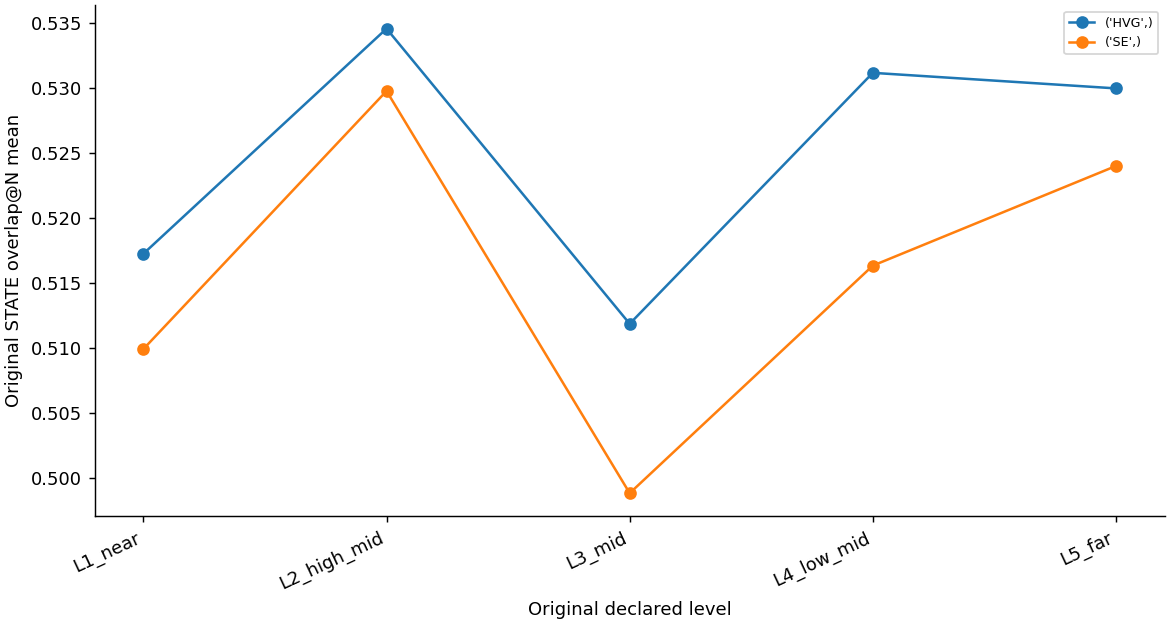

Curves are recalculated means under the original grouping rule. No new confidence bands have been added.


In [5]:
curve=ns.compare_curve('spc_tahoe_fewshot_target_context_chemical_support.csv', initial=True)
ns.show_curve(curve)

## Original agent decision and supporting diagnostics

The following records preserve the agent’s actual determination, including rejected candidates and controls. Their historical status labels are shown as recorded.

In [6]:
ledger=json.loads((rp.INITIAL/'axis_ledger.json').read_text())
display(ledger[0])


{'axis_id': 'A1_tahoe_target_context_chemical_support',
 'status': 'valid_negative_or_weak',
 'frozen_before_full_target_scoring': True,
 'schema_probe_exposure': 'One C32 ST-HVG result CSV was opened before this script for column inspection only; confirmation summaries use the full loaded Tahoe pool and are not selected by target error.',
 'unit': 'Tahoe perturbation-by-cell-context-by-dose examples, analyzed separately for ST-HVG and ST-SE',
 'axis_definition': "For each held-out Tahoe few-shot target-context drug/dose, compute RDKit Morgan Tanimoto similarity to the nearest drug that is observed in that same target context's training subset. Split into five equal-frequency levels using the similarity feature only.",
 'direction': 'L1_near has highest target-context training support; L5_far has lowest support.',
 'validity_checks': {'nontrivial_levels': 5,
  'min_rows_per_level_per_representation': 720,
  'similarity_decreases_when_ordered': True,
  'label_or_target_error_used_for_me

All source files, downloaded inputs and historical outputs are checksummed in `original_manifest.json`. The full preliminary candidate screening and download inventory are retained in notebook `00-original-downloads-and-axis-history.ipynb`.

### Replay detail: tied nearest-reference labels

All reconstructed similarities, frozen levels and checked outcome metrics match the original. In 50 records, the displayed name of the nearest reference drug differs because two reference drugs have exactly the same maximum Tanimoto similarity and the original code iterates an unordered Python set. Both pairwise similarities were checked. This does not change the curve. Per-record evidence is in `computed/initial/nearest_reference_ties.json`.

`download_manifest.json` lists all 58 score/metadata files with the recovered revision, SHA-256, byte size and a pinned download URL derived from that revision. Historical annotation snapshots are included under `original/`; current catalog URLs are not substitutes for their archived bytes.